In [1]:
# For playing a beep at the end of very long computations
from IPython.display import Audio
from IPython.core.display import display

def beep():
    sr = 22050 # sample rate
    T = 0.3    # seconds
    t = np.linspace(0, T, int(T*sr), endpoint=False) # time variable
    x = 0.5*np.sin(2*np.pi*440*t) # pure sine wave at 440 Hz
    display(Audio(x, rate=sr, autoplay=True))
    
def beepok():
    sr = 22050 # sample rate
    T = 0.3    # seconds
    t = np.linspace(0, T, int(T*sr), endpoint=False) # time variable
    x = 0.5*np.sin(2*np.pi*440*t) # pure sine wave at 440 Hz
    x1 = 0.5*np.sin(2*np.pi*300*t) # pure sine wave at 440 Hz
    display(Audio(x, rate=sr, autoplay=True))        
    display(Audio(x1, rate=sr, autoplay=True))    

In [2]:
import datetime
time_stamp = datetime.datetime.now().strftime("%m%d")
# time_stamp = datetime.datetime.now().strftime("%Y%m%d-%H%M")
print(time_stamp)

0116


# Set config

In [3]:
# ERA="ee17"
# ERA="ee17"
# ERA="mm17"
# DATE = '20230116'
# INPUTDIR = "/eos/user/h/hkwon/Run2/20230116_17/mm/"
import sys
ERA = sys.argv[1]
DATE = sys.argv[2]
INPUTDIR = sys.argv[3]

DUMP_PKL = True
RUN_SIDEBAND_MET = True
RUN_SIDEBAND_MASS = True
DUMP_SIDEBAND_MET_PKL = True
DUMP_SIDEBAND_MASS_PKL = True
EXPORT_VARIABLE = False

# Get input

In [4]:
import os
import numpy as np
import pickle
import uproot
import glob
import pandas as pd
from tqdm import tqdm
import json
## user define
sys.path.append(".")
from Util_v1 import HistStack

import ROOT as rt
import fnmatch

lumi_all={
    "ee16pre":19520,
    "ee16post":16810,
    "ee17":41480,
    "ee18":59830,
    "mm16pre":19520,
    "mm16post":16810,
    "mm17":41480,
    "mm18":59830,    
    "em16pre":19520,
    "em16post":16810,
    "em17":41480,
    "em18":59830     
}

data_evts = {
    "ee16pre":111,
    "ee16post":111,
    "ee17":111,
    "ee18":111,
    "mm16pre":111,
    "mm16post":111,
    "mm17":739073838,
    "mm18":111,    
    "em16pre":111,
    "em16post":111,
    "em17":111,
    "em18":111     
}

lumi=lumi_all[ERA]
print(ERA, lumi)

channel = ERA.replace("16pre", "")
channel = channel.replace("16post", "")
channel = channel.replace("17", "")
channel = channel.replace("18", "")

def get_df(root_file_name, unneccesary_columns):
    f = uproot.open(root_file_name)
    df = uproot.open(root_file_name)["Events_"+channel].arrays(library="pd")
    df_met_u = uproot.open(root_file_name)["Events_"+channel+"_met_u"].arrays(library="pd")
    df_met_d = uproot.open(root_file_name)["Events_"+channel+"_met_d"].arrays(library="pd")    
    info = uproot.open(root_file_name)["Info_"+channel].arrays(library="pd")
    return sum(info["sumweight"]), df.drop(unneccesary_columns, axis=1), df_met_u.drop(unneccesary_columns, axis=1), df_met_d.drop(unneccesary_columns, axis=1)

unneccesary_columns = []
dic_input = {
    "ee16pre": "/eos/user/h/hkwon/Run2/"+DATE+"_16pre/ee/",
    "mm16pre": "/eos/user/h/hkwon/Run2/"+DATE+"_16pre/mm/",
    "em16pre": "/eos/user/h/hkwon/Run2/"+DATE+"_16pre/em/",
    "ee16post": "/eos/user/h/hkwon/Run2/"+DATE+"_16post/ee/",
    "mm16post": "/eos/user/h/hkwon/Run2/"+DATE+"_16post/mm/",
    "em16post": "/eos/user/h/hkwon/Run2/"+DATE+"_16post/em/",
    "ee17": "/eos/user/h/hkwon/Run2/"+DATE+"_17/ee/",
    "mm17": "/eos/user/h/hkwon/Run2/"+DATE+"_17/mm/",
    "em17": "/eos/user/h/hkwon/Run2/"+DATE+"_17/em/",
    "ee18": "/eos/user/h/hkwon/Run2/"+DATE+"_18/ee/",
    "mm18": "/eos/user/h/hkwon/Run2/"+DATE+"_18/mm/",    
    "em18": "/eos/user/h/hkwon/Run2/"+DATE+"_18/em/"        
#     "em18": "/eos/user/h/hkwon/Run2/20221120_18/em/"        
}
# input_dir = dic_input[ERA]
input_dir = INPUTDIR
f = []
for (dirpath, dirnames, filenames) in os.walk(input_dir):
    f.extend(filenames)
    break

dic_tup={}
for file in tqdm(f):
    # file naming: flatNtuple_Preselect_WZ1.root, flatNtuple_Preselect_Zp-3700_CH-1345.root
    if not "flatNtuple" in file:
        continue
    if channel=="mm" and fnmatch.fnmatch(file, '*E*Run*'):
        continue
    if channel=="ee" and fnmatch.fnmatch(file, '*M*Run*'):
        continue
    if channel=="em" and fnmatch.fnmatch(file, '*M*Run*'):
        continue          
    if "Zp" in file:
        sample=file.split('_')[2]+"_"+file.split('_')[3]
    else:
        sample=file.split('_')[2]
    sample=sample.rstrip('.root')
    try:
        dic_tup[sample]=get_df(input_dir+file, unneccesary_columns)   
    except:
        print(sample)
        beep()        
        if "Run" in sample: # check file corrupt
            raise    
# dic_tup

Welcome to JupyROOT 6.26/08
mm17 41480


100%|██████████| 185/185 [01:19<00:00,  2.33it/s]


In [5]:
beepok()

In [6]:
# for key in dic_tup:
#     print(key)

In [7]:
# get x-sec
dic_xsec={}
with open('config/CrossSection.json') as json_file:
    data = json.load(json_file)
    dic_xsec=data
print(dic_xsec)

{'Data': 1, 'DY': 6077.22, 'TT': 88.29, 'TTSemi': 365.34, 'TTZ': 0.2432, 'top': 34.91, 'antitop': 34.91, 'WW': 10.48, 'WZ': 5.052, 'ZZ': 0.6008, 'Zp-1700_CH-345': 0.03523, 'Zp-1700_CH-595': 0.03523, 'Zp-1700_CH-845': 0.03523, 'Zp-2100_CH-345': 0.01198, 'Zp-2100_CH-595': 0.01198, 'Zp-2100_CH-845': 0.01198, 'Zp-2500_CH-345': 0.004396, 'Zp-2500_CH-595': 0.004396, 'Zp-2500_CH-845': 0.004396, 'Zp-2500_CH-1095': 0.004396, 'Zp-2900_CH-345': 0.001768, 'Zp-2900_CH-595': 0.001768, 'Zp-2900_CH-845': 0.001768, 'Zp-2900_CH-1095': 0.001768, 'Zp-2900_CH-1345': 0.001768, 'Zp-3300_CH-345': 0.000729, 'Zp-3300_CH-595': 0.000729, 'Zp-3300_CH-845': 0.000729, 'Zp-3300_CH-1095': 0.000729, 'Zp-3300_CH-1345': 0.000729, 'Zp-3300_CH-1595': 0.000729, 'Zp-3700_CH-345': 0.00031, 'Zp-3700_CH-595': 0.00031, 'Zp-3700_CH-845': 0.00031, 'Zp-3700_CH-1095': 0.00031, 'Zp-3700_CH-1345': 0.00031, 'Zp-3700_CH-1595': 0.00031, 'Zp-3700_CH-1845': 0.00031, 'Zp-4100_CH-345': 0.000135, 'Zp-4100_CH-595': 0.000135, 'Zp-4100_CH-845': 

In [8]:
Data_concat, TT_concat, TTSemi_concat, TTZ_concat, DY_concat, top_concat, antitop_concat, WW_concat, WZ_concat, ZZ_concat = ([] for i in range(10))
Data_concat_met_u, TT_concat_met_u, TTSemi_concat_met_u, TTZ_concat_met_u, DY_concat_met_u, top_concat_met_u, antitop_concat_met_u, WW_concat_met_u, WZ_concat_met_u, ZZ_concat_met_u = ([] for i in range(10))
Data_concat_met_d, TT_concat_met_d, TTSemi_concat_met_d, TTZ_concat_met_d, DY_concat_met_d, top_concat_met_d, antitop_concat_met_d, WW_concat_met_d, WZ_concat_met_d, ZZ_concat_met_d = ([] for i in range(10))

Data_nevts, TT_nevts, TTSemi_nevts, TTZ_nevts, DY_nevts, top_nevts, antitop_nevts, WW_nevts, WZ_nevts, ZZ_nevts = ([] for i in range(10))

merged_dic_df={}
for key in dic_tup:
    if fnmatch.fnmatch(key, 'DY?'):
        DY_concat.append(dic_tup[key][1])
        DY_concat_met_u.append(dic_tup[key][2])
        DY_concat_met_d.append(dic_tup[key][3])
        DY_nevts.append(dic_tup[key][0])
    if fnmatch.fnmatch(key, 'TT?'):
        TT_concat.append(dic_tup[key][1])
        TT_concat_met_u.append(dic_tup[key][2])
        TT_concat_met_d.append(dic_tup[key][3])
        TT_nevts.append(dic_tup[key][0])
    if fnmatch.fnmatch(key, 'TTSemi*'):
        TTSemi_concat.append(dic_tup[key][1])
        TTSemi_concat_met_u.append(dic_tup[key][2])
        TTSemi_concat_met_d.append(dic_tup[key][3])
        TTSemi_nevts.append(dic_tup[key][0])
    if fnmatch.fnmatch(key, 'TTZ*'):
        TTZ_concat.append(dic_tup[key][1])
        TTZ_concat_met_u.append(dic_tup[key][2])
        TTZ_concat_met_d.append(dic_tup[key][3])
        TTZ_nevts.append(dic_tup[key][0])
    if fnmatch.fnmatch(key, 'TW?'):
        top_concat.append(dic_tup[key][1])
        top_concat_met_u.append(dic_tup[key][2])
        top_concat_met_d.append(dic_tup[key][3])
        top_nevts.append(dic_tup[key][0])        
    if fnmatch.fnmatch(key, 'TWa?'):
        antitop_concat.append(dic_tup[key][1])
        antitop_concat_met_u.append(dic_tup[key][2])
        antitop_concat_met_d.append(dic_tup[key][3])
        antitop_nevts.append(dic_tup[key][0]) 
    if fnmatch.fnmatch(key, 'WW*'):
        WW_concat.append(dic_tup[key][1])
        WW_concat_met_u.append(dic_tup[key][2])
        WW_concat_met_d.append(dic_tup[key][3])
        WW_nevts.append(dic_tup[key][0])        
    if fnmatch.fnmatch(key, 'WZ*'):
        WZ_concat.append(dic_tup[key][1])
        WZ_concat_met_u.append(dic_tup[key][2])
        WZ_concat_met_d.append(dic_tup[key][3])
        WZ_nevts.append(dic_tup[key][0])
    if fnmatch.fnmatch(key, 'ZZ*'):
        ZZ_concat.append(dic_tup[key][1])
        ZZ_concat_met_u.append(dic_tup[key][2])
        ZZ_concat_met_d.append(dic_tup[key][3])
        ZZ_nevts.append(dic_tup[key][0])        
    if fnmatch.fnmatch(key, '*Run*'):
        Data_concat.append(dic_tup[key][1])
        Data_concat_met_u.append(dic_tup[key][2])
        Data_concat_met_d.append(dic_tup[key][3])
        Data_nevts.append(dic_tup[key][0]) 
    if fnmatch.fnmatch(key, 'Zp*'): 
        merged_dic_df[key]=dic_tup[key]


In [9]:
# free memory 
dic_tup.clear()

In [10]:
%%capture totalinput --no-stderr

print("######################################################")
print("####   Total input number of events (sumweight)   ####")
print("######################################################")
if TT_concat:
    merged_dic_df['TT']=sum(TT_nevts), pd.concat(TT_concat), pd.concat(TT_concat_met_u), pd.concat(TT_concat_met_d)
    print("TT:",sum(TT_nevts))
if TTSemi_concat:
    merged_dic_df['TTSemi']=sum(TTSemi_nevts), pd.concat(TTSemi_concat), pd.concat(TTSemi_concat_met_u), pd.concat(TTSemi_concat_met_d)
    print("TTSemi:",sum(TTSemi_nevts))
if TTZ_concat:
    merged_dic_df['TTZ']=sum(TTZ_nevts), pd.concat(TTZ_concat), pd.concat(TTZ_concat_met_u), pd.concat(TTZ_concat_met_d)
    print("TTZ:",sum(TTZ_nevts))    
if DY_concat:
    merged_dic_df['DY']=sum(DY_nevts), pd.concat(DY_concat), pd.concat(DY_concat_met_u), pd.concat(DY_concat_met_d)
    print("DY:",sum(DY_nevts))    
if top_concat:
    df=pd.concat(top_concat)
    merged_dic_df['top']=sum(top_nevts), pd.concat(top_concat), pd.concat(top_concat_met_u), pd.concat(top_concat_met_d)
    print("top:",sum(top_nevts))
if antitop_concat:
    df=pd.concat(antitop_concat)
    merged_dic_df['antitop']=sum(antitop_nevts), pd.concat(antitop_concat), pd.concat(antitop_concat_met_u), pd.concat(antitop_concat_met_d)
    print("antitop:",sum(antitop_nevts))   
if ZZ_concat:
    df=pd.concat(ZZ_concat)
    merged_dic_df['ZZ']=sum(ZZ_nevts), pd.concat(ZZ_concat), pd.concat(ZZ_concat_met_u), pd.concat(ZZ_concat_met_d)
    print("ZZ:",sum(ZZ_nevts))  
if WZ_concat:
    df=pd.concat(WZ_concat)
    merged_dic_df['WZ']=sum(WZ_nevts), pd.concat(WZ_concat), pd.concat(WZ_concat_met_u), pd.concat(WZ_concat_met_d)
    print("WZ:",sum(WZ_nevts))  
if WW_concat:
    df=pd.concat(WW_concat)
    merged_dic_df['WW']=sum(WW_nevts), pd.concat(WW_concat), pd.concat(WW_concat_met_u), pd.concat(WW_concat_met_d)
    print("WW:",sum(WW_nevts)) 
if Data_concat:
    merged_dic_df['Data']=sum(Data_nevts), pd.concat(Data_concat), pd.concat(Data_concat_met_u), pd.concat(Data_concat_met_d)
    print("Data:",sum(Data_nevts))      
# merged_dic_df["Zp-2500"]=dic_tup["Zp-2500"][0], dic_tup["Zp-2500"][1] 


In [11]:
os.system("mkdir -p "+DATE+"/Presel/"+ERA)
with open(DATE+"/Presel/"+ERA+'/Nevents.txt', 'w') as f:
    f.write(totalinput.stdout)

In [12]:
# try:
#     if data_evts[ERA]!=sum(Data_nevts):
#         raise ValueError('Data events missing!')
# except (ValueError, IndexError):
#     raise

In [13]:
%%capture eventweights --no-stderr
sys = ["puweight_pre", "l1prefiring_pre", 'effSF_pre', 'topSFAlt_pre', 'genweight_pre']
print("####################################################")
print("####       event weights (normalization)        ####")
print("####################################################")
def get_dic_with_weight(merged_dic_df):
    dic_df={}
    dic_df_met_u={}
    dic_df_met_d={}
    for key, vs in merged_dic_df.items():
        print(key)
        if "16pre" in ERA and key=="Zp-2500_CH-595": # signal sample missing
            continue    
        if "Data" in key:
            norm=1
        else:
            norm=lumi*dic_xsec[key]/vs[0]
        print(key, ":", norm)
        dic_df[key]=vs[1]
        dic_df_met_u[key] = vs[2]
        dic_df_met_d[key]=vs[3]
        dic_df[key]["weight"] = vs[1]["genweight_pre"]*norm
        dic_df_met_u[key]["weight"] = vs[1]["genweight_pre"]*norm
        dic_df_met_d[key]["weight"] = vs[1]["genweight_pre"]*norm
        dic_df[key]["wopu"] = vs[1]["genweight_pre"]*norm
        dic_df[key]["wol1"] = vs[1]["genweight_pre"]*norm
        dic_df[key]["woeff"] = vs[1]["genweight_pre"]*norm
        dic_df[key]["wotop"] = vs[1]["genweight_pre"]*norm       
        for s in sys:
            if s=="genweight_pre":
                continue
            dic_df[key]["weight"] *= vs[1][s]
            dic_df_met_u[key]["weight"] *= vs[1][s]
            dic_df_met_d[key]["weight"] *= vs[1][s]
            # n-1 correction
            if s!="puweight_pre":
                dic_df[key]["wopu"] *= vs[1][s]
            if s!="l1prefiring_pre":
                dic_df[key]["wol1"] *= vs[1][s]
            if s!="effSF_pre":
                dic_df[key]["woeff"] *= vs[1][s]
            if s!="topSF_pre":
                dic_df[key]["wotop"] *= vs[1][s]
        # up, down    
        for s1 in sys:
            #if "top" in s1 or "eff" in s1:
            if "top" in s1:
                continue
            s_u = s1.replace("_", "_u_")
            s_d = s1.replace("_", "_d_")
            if s1=="genweight_pre":
                dic_df[key]["weight"+s_u.replace('_u_pre', 'Up')] = dic_df[key]["weight"].copy(deep=True)*np.fabs(dic_df[key][s_u])
                dic_df[key]["weight"+s_d.replace('_d_pre', 'Down')] = dic_df[key]["weight"].copy(deep=True)*np.fabs(dic_df[key][s_d])
            else:
                dic_df[key]["weight"+s_u.replace('_u_pre', 'Up')] = dic_df[key]["weight"].copy(deep=True)/dic_df[key][s1]*dic_df[key][s_u]
                dic_df[key]["weight"+s_d.replace('_d_pre', 'Down')] = dic_df[key]["weight"].copy(deep=True)/dic_df[key][s1]*dic_df[key][s_d]             
    return dic_df, dic_df_met_u, dic_df_met_d

dic_df, dic_df_met_u, dic_df_met_d = get_dic_with_weight(merged_dic_df)

In [14]:
with open(DATE+"/Presel/"+ERA+'/Nevents.txt', 'a') as f:
    f.write(eventweights.stdout)

# Preselection

In [15]:
%%capture weihtedevents --no-stderr
dic_df_raw={}
query_str="mass_pre>100 and pt_lead_pre>80 and pt_trail_pre>40 and PuppiMET_pre>100"
# query_str="mass_pre>100 and pt_lead_pre>80 and pt_trail_pre>40 and MET_pre>80"
# query_str="mass_pre>60"

print("#############################################################")
print("####   unweighted (weighted) #events after preselection  ####")
print("#############################################################")
for key in dic_df:  
    dic_df_raw[key]=dic_df[key].query(query_str)
    dic_df_met_u[key]=dic_df_met_u[key].query(query_str)
    dic_df_met_d[key]=dic_df_met_d[key].query(query_str)
    unweighted_nevt = dic_df_raw[key].shape[0]
    print(key, ":", unweighted_nevt, "(", sum(dic_df_raw[key]["weight"]), ")")
#     print(key, ":", unweighted_nevt, "(", unweighted_nevt*lumi*dic_xsec[key]/merged_dic_df[key][0], ")")

nested_dic_df={}
nested_dic_df["raw"]=dic_df_raw
nested_dic_df["met_u"]=dic_df_met_u
nested_dic_df["met_d"]=dic_df_met_d

In [16]:
with open(DATE+"/Presel/"+ERA+'/Nevents.txt', 'a') as f:
    f.write(weihtedevents.stdout)

In [17]:
if DUMP_PKL:
    os.system("mkdir -p "+DATE+"/Presel/"+ERA)
    print("Dump pickle")
    with open(DATE+"/Presel/"+ERA+"/"+"nested_dic_df.pkl", "wb") as f:
        pickle.dump(nested_dic_df, f)

Dump pickle


# Draw

In [18]:
# draw
# get plot configuration
dic_variable={
    "PuppiMET_pre": [28, 100, 660, "Puppi p_{T}^{miss} [GeV]"],    
    "mass_pre": [30, 100, 700, "M_{ll} [GeV]"],
    "pt_lead_pre": [31, 80,  660, "p_{T}(l_{lead}) [GeV]"],
    "pt_trail_pre": [30, 40, 520, "p_{T}(l_{trail}) [GeV]"],
    "Zpt_pre": [50, 0, 500, "p_{T}(ll) [GeV]"],
    "MT_pre": [55, 0, 550, "M_{T} [GeV]"],
    "MT2_pre": [35, 0, 350, "M_{T2} [GeV]"],
    "U_pre": [29, 0, 660, "U [GeV]"],
    "JZB_pre": [29, 80, 660, "JZB"],
    "dPhill_pre": [17, 0, 3.4, "#Delta#phi(l,l)"],
    "dPhilMET_pre": [17, 0, 3.4, "#Delta#phi(l,p_{T}^{miss})"],
    "dRll_pre": [30, 0, 6, "#DeltaR(l,l)"],
    "dPhillMET_pre": [17, 0, 3.4, "#Delta#phi(ll,p_{T}^{miss})"],
#     "MC1C1_pre": [36, 180, 900, "MC1C1 [GeV]"], 
#     "H3PP_pre": [41, 80, 900, "H3PP [GeV]"], 
#     "H3TPP_pre": [40, 0, 800, "H3TPP [GeV]"], 
    "eta_lead_pre": [30, -3, 3, "#eta(l_{lead})"],
    "eta_trail_pre": [30, -3, 3, "#eta(l_{trail})"],
    "phi_lead_pre": [40, -4, 4, "#phi(l_{lead})"],
    "phi_trail_pre": [40, -4, 4, "#phi(l_{trail})"], 
    "PuppiMET_phi_pre": [40, -4, 4, "Puppi p_{T}^{miss} #phi(l_{trail})"],     
}

{'TTZ': 13.466666901068264, 'ZZ': 20.418093202591272, 'WZ': 73.5581678138181, 'WW': 486.9918720615664, 'TW': 1057.6594272009095, 'TT': 10369.169285324386, 'DY': 464.31868175720086, 'Zp-2500_CH-345': 20.548673345630572, 'Data': 12527.0}
array('f', [13.466667175292969, 20.418092727661133, 73.55816650390625, 486.99188232421875, 1057.659423828125, 10369.1689453125, 464.3186950683594, 20.548673629760742])
test
40
{'TTZ': 13.466666901068264, 'ZZ': 20.418093202591272, 'WZ': 73.5581678138181, 'WW': 486.9918720615664, 'TW': 1057.6594272009095, 'TT': 10369.169285324386, 'DY': 464.31868175720086, 'Zp-2500_CH-345': 20.548673345630572, 'Data': 12527.0}
array('f', [13.466667175292969, 20.418092727661133, 73.55816650390625, 486.99188232421875, 1057.659423828125, 10369.1689453125, 464.3186950683594, 20.548673629760742])
test
40


Info in <TCanvas::Print>: pdf file 20230116/Presel/mm17/weight/preselv1_mass_pre>100 and pt_lead_pre>80 and pt_trail_pre>40 and PuppiMET_pre>100_PuppiMET_pre.pdf has been created
Info in <TCanvas::Print>: png file 20230116/Presel/mm17/weight/preselv1_mass_pre>100 and pt_lead_pre>80 and pt_trail_pre>40 and PuppiMET_pre>100_PuppiMET_pre.png has been created
Warning in <TCanvas::Constructor>: Deleting canvas with same name: c1
Info in <TCanvas::Print>: pdf file 20230116/Presel/mm17/weight/preselv1_mass_pre>100 and pt_lead_pre>80 and pt_trail_pre>40 and PuppiMET_pre>100_mass_pre.pdf has been created
Info in <TCanvas::Print>: png file 20230116/Presel/mm17/weight/preselv1_mass_pre>100 and pt_lead_pre>80 and pt_trail_pre>40 and PuppiMET_pre>100_mass_pre.png has been created
Warning in <TCanvas::Constructor>: Deleting canvas with same name: c1
Info in <TCanvas::Print>: pdf file 20230116/Presel/mm17/weight/preselv1_mass_pre>100 and pt_lead_pre>80 and pt_trail_pre>40 and PuppiMET_pre>100_pt_lead

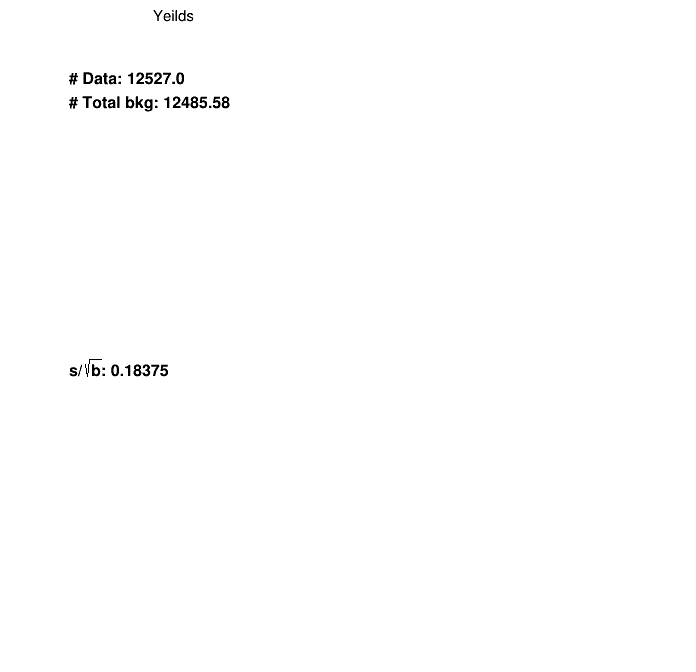

In [19]:
sys_list = ["weight", "wotop"]
for sys_key in sys_list:
    for variable, r in dic_variable.items():
        os.system("mkdir -p "+DATE+"/Presel/"+ERA+"/"+sys_key)
        hist=HistStack(dic_df_raw, variable, sys_key, r[0], r[1], r[2], r[3])            
        c1=hist.draw_hist("Zp-2500_CH-345", ERA, file_name=DATE+"/Presel/"+ERA+"/"+sys_key+"/preselv1_"+query_str, is_dnn=False) 

    #simply from last instance
    print(hist.get_yeilds())
    hist.draw_pie(file_name=DATE+"/Presel/"+ERA+"/"+sys_key+"/pie_"+query_str)
    print(hist.nbin)

# MET side band

In [20]:
if RUN_SIDEBAND_MET:
    dic_df_raw={}
    # query_str="mass_pre<100 and pt_lead_pre>80 and pt_trail_pre>40 and PuppiMET_pre>100"
    query_str="mass_pre>100 and pt_lead_pre>80 and pt_trail_pre>40 and PuppiMET_pre<100 and PuppiMET_pre>80"
    # query_str="mass_pre>100 and pt_lead_pre>80 and pt_trail_pre>40 and MET_pre>80"
    # query_str="mass_pre>60"

    print("####################################################")
    print("####   (unweighted) #events after preselection  ####")
    print("####################################################")
    for key in dic_df:  
        dic_df_raw[key]=dic_df[key].query(query_str)
        dic_df_met_u[key]=dic_df_met_u[key].query(query_str)
        dic_df_met_d[key]=dic_df_met_d[key].query(query_str)     
        print(key, ":", dic_df_raw[key].shape[0])
    #     print("num of", key, ":", dic_df_jes_u[key].shape[0])
    #     print("num of", key, ":", dic_df_jes_d[key].shape[0])
    nested_dic_df={}
    nested_dic_df["raw"]=dic_df_raw
    nested_dic_df["met_u"]=dic_df_met_u
    nested_dic_df["met_d"]=dic_df_met_d    

####################################################
####   (unweighted) #events after preselection  ####
####################################################
Zp-1700_CH-345 : 1930
Zp-1700_CH-595 : 1475
Zp-1700_CH-845 : 1174
Zp-2100_CH-345 : 1854
Zp-2100_CH-595 : 1486
Zp-2100_CH-845 : 1208
Zp-2500_CH-345 : 1620
Zp-2500_CH-595 : 1324
Zp-2500_CH-845 : 1086
Zp-2900_CH-1095 : 833
Zp-2900_CH-1345 : 650
Zp-2900_CH-345 : 1508
Zp-2900_CH-595 : 1239
Zp-2900_CH-845 : 1009
Zp-3300_CH-1095 : 741
Zp-3300_CH-1345 : 648
Zp-3300_CH-1595 : 514
Zp-3300_CH-345 : 1389
Zp-3300_CH-595 : 1198
Zp-3700_CH-1095 : 669
Zp-3700_CH-1345 : 567
Zp-3700_CH-1595 : 528
Zp-3700_CH-1845 : 452
Zp-3700_CH-345 : 1304
Zp-3700_CH-595 : 1076
Zp-3700_CH-845 : 914
Zp-4100_CH-1095 : 668
Zp-4100_CH-1345 : 553
Zp-4100_CH-1595 : 460
Zp-4100_CH-1845 : 402
Zp-4100_CH-345 : 1292
Zp-4100_CH-595 : 1020
Zp-4100_CH-845 : 803
TT : 183748
TTSemi : 442
TTZ : 6131
DY : 719
top : 1218
antitop : 1236
ZZ : 10402
WZ : 2125
WW : 5055
Data : 7964


In [21]:
if DUMP_SIDEBAND_MET_PKL:
    with open(DATE+"/Presel/"+ERA+"/"+"nested_dic_df_METSB.pkl", "wb") as f:
        pickle.dump(nested_dic_df, f)

{'TTZ': 4.084153247771, 'ZZ': 6.039388934992322, 'WZ': 32.51309645216655, 'WW': 294.2215604349771, 'TW': 586.1495267330488, 'TT': 5813.010264800402, 'DY': 801.3440724160654, 'Zp-2500_CH-345': 1.89617120814965, 'Data': 7964.0}
array('f', [4.084153175354004, 6.039389133453369, 32.51309585571289, 294.2215576171875, 586.1495361328125, 5813.01025390625, 801.3440551757812, 1.89617121219635])
test
40
{'TTZ': 4.084153247771, 'ZZ': 6.039388934992322, 'WZ': 32.51309645216655, 'WW': 294.2215604349771, 'TW': 586.1495267330488, 'TT': 5813.010264800402, 'DY': 801.3440724160654, 'Zp-2500_CH-345': 1.89617120814965, 'Data': 7964.0}
array('f', [4.084153175354004, 6.039389133453369, 32.51309585571289, 294.2215576171875, 586.1495361328125, 5813.01025390625, 801.3440551757812, 1.89617121219635])
test
40


Warning in <TCanvas::Constructor>: Deleting canvas with same name: c1
Info in <TCanvas::Print>: pdf file 20230116/Presel/mm17/METSB/weight/preselv1_mass_pre>100 and pt_lead_pre>80 and pt_trail_pre>40 and PuppiMET_pre<100 and PuppiMET_pre>80_PuppiMET_pre.pdf has been created
Info in <TCanvas::Print>: png file 20230116/Presel/mm17/METSB/weight/preselv1_mass_pre>100 and pt_lead_pre>80 and pt_trail_pre>40 and PuppiMET_pre<100 and PuppiMET_pre>80_PuppiMET_pre.png has been created
Warning in <TCanvas::Constructor>: Deleting canvas with same name: c1
Info in <TCanvas::Print>: pdf file 20230116/Presel/mm17/METSB/weight/preselv1_mass_pre>100 and pt_lead_pre>80 and pt_trail_pre>40 and PuppiMET_pre<100 and PuppiMET_pre>80_mass_pre.pdf has been created
Info in <TCanvas::Print>: png file 20230116/Presel/mm17/METSB/weight/preselv1_mass_pre>100 and pt_lead_pre>80 and pt_trail_pre>40 and PuppiMET_pre<100 and PuppiMET_pre>80_mass_pre.png has been created
Warning in <TCanvas::Constructor>: Deleting canv

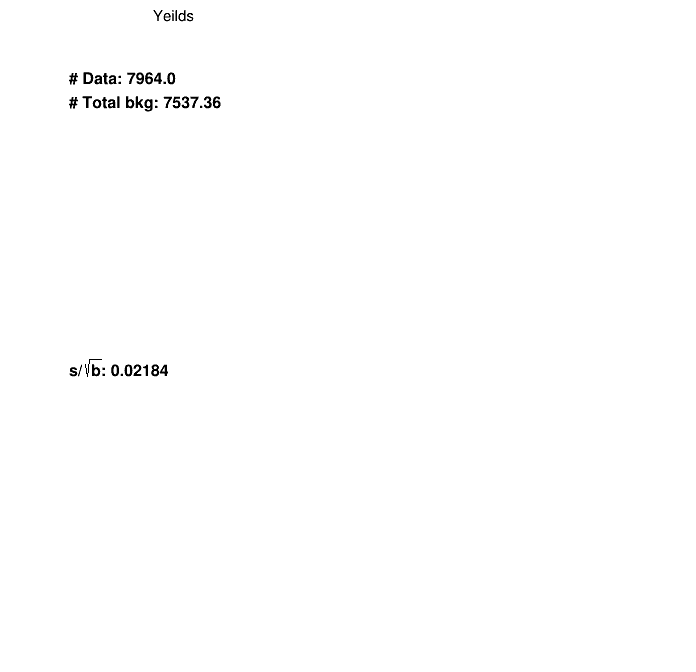

In [22]:
dic_variable={
    "PuppiMET_pre": [20, 0, 100, "Puppi p_{T}^{miss} [GeV]"],    
    "mass_pre": [30, 100, 700, "M_{ll} [GeV]"],
    "pt_lead_pre": [31, 80,  660, "p_{T}(l_{lead}) [GeV]"],
    "pt_trail_pre": [30, 40, 520, "p_{T}(l_{trail}) [GeV]"],
    "Zpt_pre": [50, 0, 500, "p_{T}(ll) [GeV]"],
    "MT_pre": [55, 0, 550, "M_{T} [GeV]"],
    "MT2_pre": [35, 0, 350, "M_{T2} [GeV]"],
    "U_pre": [29, 0, 660, "U [GeV]"],
    "JZB_pre": [29, 80, 660, "JZB"],
    "dPhill_pre": [17, 0, 3.4, "#Delta#phi(l,l)"],
    "dPhilMET_pre": [17, 0, 3.4, "#Delta#phi(l,p_{T}^{miss})"],
    "dRll_pre": [30, 0, 6, "#DeltaR(l,l)"],
    "dPhillMET_pre": [17, 0, 3.4, "#Delta#phi(ll,p_{T}^{miss})"],
#     "MC1C1_pre": [36, 180, 900, "MC1C1 [GeV]"], 
#     "H3PP_pre": [41, 80, 900, "H3PP [GeV]"], 
#     "H3TPP_pre": [40, 0, 800, "H3TPP [GeV]"], 
    "eta_lead_pre": [30, -3, 3, "#eta(l_{lead})"],
    "eta_trail_pre": [30, -3, 3, "#eta(l_{trail})"],
    "phi_lead_pre": [40, -4, 4, "#phi(l_{lead})"],
    "phi_trail_pre": [40, -4, 4, "#phi(l_{trail})"], 
    "PuppiMET_phi_pre": [40, -4, 4, "Puppi p_{T}^{miss} #phi(l_{trail})"],      
}

sys_list = ["weight", "wotop"]
for sys_key in sys_list:
    for variable, r in dic_variable.items():
        os.system("mkdir -p "+DATE+"/Presel/"+ERA+"/METSB/"+sys_key)
        hist=HistStack(dic_df_raw, variable, sys_key, r[0], r[1], r[2], r[3])            
        c1=hist.draw_hist("Zp-2500_CH-345", ERA, file_name=DATE+"/Presel/"+ERA+"/METSB/"+sys_key+"/preselv1_"+query_str, is_dnn=False) 

    #simply from last instance
    print(hist.get_yeilds())
    hist.draw_pie(file_name=DATE+"/Presel/"+ERA+"/METSB/"+sys_key+"/pie_"+query_str)
    print(hist.nbin)

# Mass side band

In [23]:
if RUN_SIDEBAND_MASS and not "em" in ERA:
    dic_df_raw={}
    # query_str="mass_pre<100 and pt_lead_pre>80 and pt_trail_pre>40 and PuppiMET_pre>100"
    query_str="mass_pre<100 and pt_lead_pre>80 and pt_trail_pre>40 and PuppiMET_pre>100"
    # query_str="mass_pre>100 and pt_lead_pre>80 and pt_trail_pre>40 and MET_pre>80"
    # query_str="mass_pre>60"

    print("####################################################")
    print("####   (unweighted) #events after preselection  ####")
    print("####################################################")
    for key in dic_df:  
        dic_df_raw[key]=dic_df[key].query(query_str)
        dic_df_met_u[key]=dic_df_met_u[key].query(query_str)
        dic_df_met_d[key]=dic_df_met_d[key].query(query_str)     
        print(key, ":", dic_df_raw[key].shape[0])
    #     print("num of", key, ":", dic_df_jes_u[key].shape[0])
    #     print("num of", key, ":", dic_df_jes_d[key].shape[0])
    nested_dic_df={}
    nested_dic_df["raw"]=dic_df_raw
    nested_dic_df["met_u"]=dic_df_met_u
    nested_dic_df["met_d"]=dic_df_met_d

####################################################
####   (unweighted) #events after preselection  ####
####################################################
Zp-1700_CH-345 : 29
Zp-1700_CH-595 : 575
Zp-1700_CH-845 : 1526
Zp-2100_CH-345 : 8
Zp-2100_CH-595 : 222
Zp-2100_CH-845 : 784
Zp-2500_CH-345 : 2
Zp-2500_CH-595 : 106
Zp-2500_CH-845 : 433
Zp-2900_CH-1095 : 456
Zp-2900_CH-1345 : 736
Zp-2900_CH-345 : 3
Zp-2900_CH-595 : 44
Zp-2900_CH-845 : 258
Zp-3300_CH-1095 : 299
Zp-3300_CH-1345 : 471
Zp-3300_CH-1595 : 586
Zp-3300_CH-345 : 3
Zp-3300_CH-595 : 31
Zp-3700_CH-1095 : 227
Zp-3700_CH-1345 : 325
Zp-3700_CH-1595 : 411
Zp-3700_CH-1845 : 462
Zp-3700_CH-345 : 2
Zp-3700_CH-595 : 13
Zp-3700_CH-845 : 118
Zp-4100_CH-1095 : 166
Zp-4100_CH-1345 : 242
Zp-4100_CH-1595 : 289
Zp-4100_CH-1845 : 369
Zp-4100_CH-345 : 1
Zp-4100_CH-595 : 8
Zp-4100_CH-845 : 64
TT : 15948
TTSemi : 906
TTZ : 57301
DY : 1538
top : 104
antitop : 85
ZZ : 225374
WZ : 22000
WW : 768
Data : 3397


In [24]:
if DUMP_SIDEBAND_MASS_PKL and not "em" in ERA:
    with open(DATE+"/Presel/"+ERA+"/"+"nested_dic_df_MASS.pkl", "wb") as f:
        pickle.dump(nested_dic_df, f)

{'TTZ': 35.505722133898274, 'ZZ': 130.7105048183524, 'WZ': 326.958320378954, 'WW': 43.956963614565105, 'TW': 44.16861754110352, 'TT': 532.0581873794131, 'DY': 1647.8162488595133, 'Zp-2500_CH-345': 0.0025074954891936055, 'Data': 3397.0}
array('f', [35.50572204589844, 130.71051025390625, 326.95831298828125, 43.95696258544922, 44.168617248535156, 532.0581665039062, 1647.8162841796875, 0.0025074954610317945])
test
40
{'TTZ': 35.505722133898274, 'ZZ': 130.7105048183524, 'WZ': 326.958320378954, 'WW': 43.956963614565105, 'TW': 44.16861754110352, 'TT': 532.0581873794131, 'DY': 1647.8162488595133, 'Zp-2500_CH-345': 0.0025074954891936055, 'Data': 3397.0}
array('f', [35.50572204589844, 130.71051025390625, 326.95831298828125, 43.95696258544922, 44.168617248535156, 532.0581665039062, 1647.8162841796875, 0.0025074954610317945])
test
40


Warning in <TCanvas::Constructor>: Deleting canvas with same name: c1
Info in <TCanvas::Print>: pdf file 20230116/Presel/mm17/MASSSB/weight/preselv1_mass_pre<100 and pt_lead_pre>80 and pt_trail_pre>40 and PuppiMET_pre>100_PuppiMET_pre.pdf has been created
Info in <TCanvas::Print>: png file 20230116/Presel/mm17/MASSSB/weight/preselv1_mass_pre<100 and pt_lead_pre>80 and pt_trail_pre>40 and PuppiMET_pre>100_PuppiMET_pre.png has been created
Warning in <TCanvas::Constructor>: Deleting canvas with same name: c1
Info in <TCanvas::Print>: pdf file 20230116/Presel/mm17/MASSSB/weight/preselv1_mass_pre<100 and pt_lead_pre>80 and pt_trail_pre>40 and PuppiMET_pre>100_mass_pre.pdf has been created
Info in <TCanvas::Print>: png file 20230116/Presel/mm17/MASSSB/weight/preselv1_mass_pre<100 and pt_lead_pre>80 and pt_trail_pre>40 and PuppiMET_pre>100_mass_pre.png has been created
Warning in <TCanvas::Constructor>: Deleting canvas with same name: c1
Info in <TCanvas::Print>: pdf file 20230116/Presel/mm1

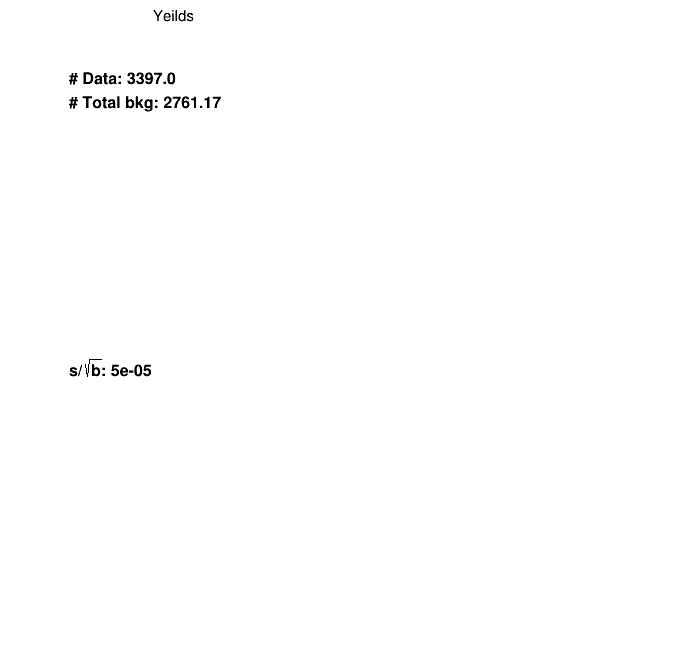

In [25]:
if not "em" in ERA:
    dic_variable={
        "PuppiMET_pre": [28, 100, 660, "Puppi p_{T}^{miss} [GeV]"],    
        "mass_pre": [20, 0, 100, "M_{ll} [GeV]"],
        "pt_lead_pre": [31, 80,  660, "p_{T}(l_{lead}) [GeV]"],
        "pt_trail_pre": [30, 40, 520, "p_{T}(l_{trail}) [GeV]"],
        "eta_lead_pre": [30, -3, 3, "#eta(l_{lead})"],
        "eta_trail_pre": [30, -3, 3, "#eta(l_{trail})"],
        "phi_lead_pre": [40, -4, 4, "#phi(l_{lead})"],
        "phi_trail_pre": [40, -4, 4, "#phi(l_{trail})"], 
        "PuppiMET_phi_pre": [40, -4, 4, "Puppi p_{T}^{miss} #phi(l_{trail})"],     
    }

    sys_list = ["weight", "wotop"]
    for sys_key in sys_list:
        for variable, r in dic_variable.items():
            os.system("mkdir -p "+DATE+"/Presel/"+ERA+"/MASSSB/"+sys_key)
            hist=HistStack(dic_df_raw, variable, sys_key, r[0], r[1], r[2], r[3])            
            c1=hist.draw_hist("Zp-2500_CH-345", ERA, file_name=DATE+"/Presel/"+ERA+"/MASSSB/"+sys_key+"/preselv1_"+query_str, is_dnn=False) 

        #simply from last instance
        print(hist.get_yeilds())
        hist.draw_pie(file_name=DATE+"/Presel/"+ERA+"/MASSSB/"+sys_key+"/pie_"+query_str)
        print(hist.nbin)

# Export variables

In [26]:
if EXPORT_VARIABLE:
    # draw
    # get plot configuration
    dic_variable={
    #     "pt_trail_pre": [8, 40, 300, "p_{T}(l_{trail}) [GeV]"],
    #     "MT2_pre": [8, 0, 160, "M_{T2} [GeV]"],
        "H3PP_pre": [19, 95, 900, "H3PP [GeV]"],     
    }
    sys_src={
        "presel":["effSF_pre", "l1prefiring_pre", "puweight_pre"]
    #     "presel":["effSF_pre", "l1prefiring_pre", "puweight_pre", "topSF_pre"]
    }
    # sys_src=[]
    for key in dic_df_raw:
        if "Zp" in key:
            for variable, r in dic_variable.items():
                hist=HistStack(dic_df_raw, variable, sys_src, "presel", r[0], r[1], r[2], r[3])            
                c1=hist.draw_hist(key, ERA, ERA+"_exportdev"+query_str, True) 
                hist.create_root_file(key, variable, channel)
                hist.export_hist(key, variable, channel, "") 

    #simply from last instance
    print(hist.get_yeilds())
    hist.draw_pie()
    print(hist.nbin)


# Signal Acc x Eff x presel

Warning in <TCanvas::Constructor>: Deleting canvas with same name: c1
Info in <TCanvas::Print>: pdf file sigeff_mm17.pdf has been created


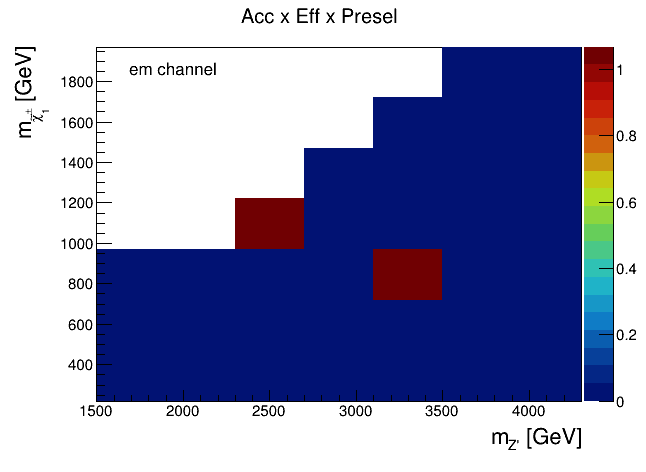

In [27]:
Zp_mass=[1700, 2100, 2500, 2900, 3300, 3700, 4100]
CH_mass=[345, 595, 845, 1095, 1345, 1595, 1845]
c1=rt.TCanvas("c1", "c1", 650, 500)
c1.SetLeftMargin(0.15)
c1.SetBottomMargin(0.15)
h2d1=rt.TH2D("h2d1", "", len(Zp_mass), Zp_mass[0]-200, Zp_mass[-1]+200, len(CH_mass), CH_mass[0]-125, CH_mass[-1]+125)
h2d1.SetTitle("Acc x Eff x Presel")

n_sig_in = 150000/4
if "em" in ERA:
    n_sig_in = 150000/2

for key in dic_df_raw:
    if not "Zp" in key:
        continue
    tmp=key.replace('_', '-')
    tmp=tmp.split('-')
    
    MZp=tmp[1]
    MCH=tmp[3]
    binx=Zp_mass.index(int(MZp))+1
    biny=CH_mass.index(int(MCH))+1
    h2d1.SetBinContent(binx, biny, dic_df_raw[key].shape[0]/(n_sig_in))
# missing bin by hand
h2d1.SetBinContent(5, 3, 40000/(n_sig_in)) #mumu: 23500, #ee: 20000
h2d1.SetBinContent(3, 4, 40000/(n_sig_in)) #mumu: 23500, #ee: 20000

# set_palette("rainbow",255)
rt.gStyle.SetOptStat(0)
rt.gStyle.SetPalette(55)

h2d1.Draw("colz")
h2d1.SetYTitle("m_{#tilde#chi_{1}^{#pm}} [GeV]")
h2d1.SetXTitle("m_{Z'} [GeV]")
h2d1.GetYaxis().SetTitleSize(0.05)
h2d1.GetXaxis().SetTitleSize(0.05)
latex=rt.TLatex()
latex.DrawLatexNDC( 0.2,0.84, "#scale[0.8]{#font[42]{"+"em channel}}")

c1.Draw()
c1.SaveAs("sigeff_"+ERA+".pdf")